In [1]:
# Decision Tree 
# Task 1: Data Preparation
import pandas as pd
import numpy as np

# Load dataset from the 'Heart_disease' sheet
df = pd.read_excel('heart_disease.xlsx', sheet_name='Heart_disease')
print("Dataset Shape:", df.shape)
print(df.head())

Dataset Shape: (908, 13)
   age   sex               cp  trestbps  chol    fbs         restecg  thalch  \
0   63  Male   typical angina       145   233   True  lv hypertrophy     150   
1   41  Male  atypical angina       135   203  False          normal     132   
2   57  Male     asymptomatic       140   192  False          normal     148   
3   52  Male   typical angina       118   186  False  lv hypertrophy     190   
4   57  Male     asymptomatic       110   201  False          normal     126   

   exang  oldpeak        slope          thal  num  
0  False      2.3  downsloping  fixed defect    0  
1  False      0.0         flat  fixed defect    0  
2  False      0.4         flat  fixed defect    0  
3  False      0.0         flat  fixed defect    0  
4   True      1.5         flat  fixed defect    0  


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 908 entries, 0 to 907
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       908 non-null    int64  
 1   sex       908 non-null    object 
 2   cp        908 non-null    object 
 3   trestbps  908 non-null    int64  
 4   chol      908 non-null    int64  
 5   fbs       908 non-null    bool   
 6   restecg   908 non-null    object 
 7   thalch    908 non-null    int64  
 8   exang     908 non-null    object 
 9   oldpeak   846 non-null    float64
 10  slope     908 non-null    object 
 11  thal      908 non-null    object 
 12  num       908 non-null    int64  
dtypes: bool(1), float64(1), int64(5), object(6)
memory usage: 86.1+ KB
None

Missing Values:
 age          0
sex          0
cp           0
trestbps     0
chol         0
fbs          0
restecg      0
thalch       0
exang        0
oldpeak     62
slope        0
thal         0
num          0
dtype: int64

Summar

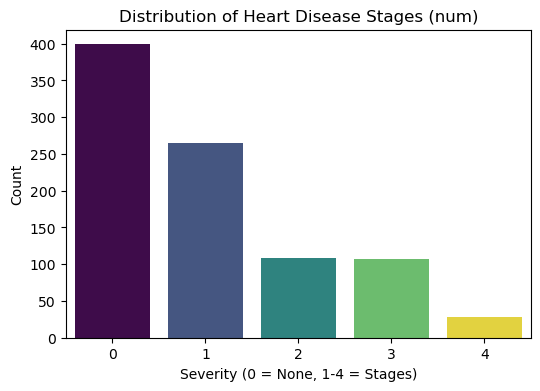

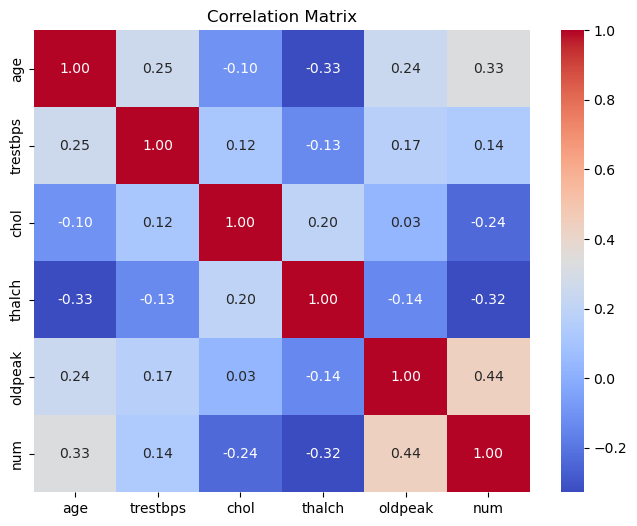

In [2]:
#Task 2: Exploratory Data Analysis (EDA)
import matplotlib.pyplot as plt
import seaborn as sns

# Check data info & missing values
print(df.info())
print("\nMissing Values:\n", df.isnull().sum())

# Summary statistics
print("\nSummary Statistics:\n", df.describe())

# Visualize target distribution ('num')
plt.figure(figsize=(6, 4))
sns.countplot(x='num', hue='num', data=df, palette='viridis', legend=False)
plt.title('Distribution of Heart Disease Stages (num)')
plt.xlabel('Severity (0 = None, 1-4 = Stages)')
plt.ylabel('Count')
plt.show()

# Correlation Matrix (on numerical columns)
plt.figure(figsize=(8, 6))
sns.heatmap(df.select_dtypes(include=[np.number]).corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

In [3]:
#Task 3: Feature Engineering
# 1. Handle missing values (Impute 'oldpeak' with median)
df['oldpeak'] = df['oldpeak'].fillna(df['oldpeak'].median())

# 2. Convert target 'num' to binary classification (0: No disease, 1: Disease present)
df['target'] = df['num'].apply(lambda x: 0 if x == 0 else 1)
df = df.drop(columns=['num'])

# 3. Encode categorical variables using One-Hot Encoding
cat_cols = ['sex', 'cp', 'restecg', 'exang', 'slope', 'thal']
df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)

print("Processed dataset shape:", df_encoded.shape)

Processed dataset shape: (908, 20)


In [4]:
#Task 4: Decision Tree Classification
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

# Separate features (X) and target (y)
X = df_encoded.drop(columns=['target'])
y = df_encoded['target']

# 80-20 Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Initialize & Train Decision Tree Classifier
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

# Predictions
y_pred = dt_model.predict(X_test)
y_prob = dt_model.predict_proba(X_test)[:, 1]

# Evaluation Metrics
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob):.4f}")

Accuracy:  0.7033
Precision: 0.7400
Recall:    0.7255
F1-Score:  0.7327
ROC-AUC:   0.7002


In [5]:
#Task 5: Hyperparameter Tuning
from sklearn.model_selection import GridSearchCV

param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [3, 4, 5, 6, 8, 10, None],
    'min_samples_split': [2, 5, 10, 15],
    'min_samples_leaf': [1, 2, 4, 8]
}

grid_search = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid, cv=5, scoring='f1')
grid_search.fit(X_train, y_train)

print("Best Hyperparameters:", grid_search.best_params_)
print(f"Best Cross-Validation F1-Score: {grid_search.best_score_:.4f}")

# Train tuned model
best_dt = grid_search.best_estimator_
y_pred_tuned = best_dt.predict(X_test)
print(f"Tuned Test Accuracy: {accuracy_score(y_test, y_pred_tuned):.4f}")
print(f"Tuned Test F1-Score: {f1_score(y_test, y_pred_tuned):.4f}")

Best Hyperparameters: {'criterion': 'entropy', 'max_depth': 6, 'min_samples_leaf': 8, 'min_samples_split': 2}
Best Cross-Validation F1-Score: 0.8133
Tuned Test Accuracy: 0.7143
Tuned Test F1-Score: 0.7500


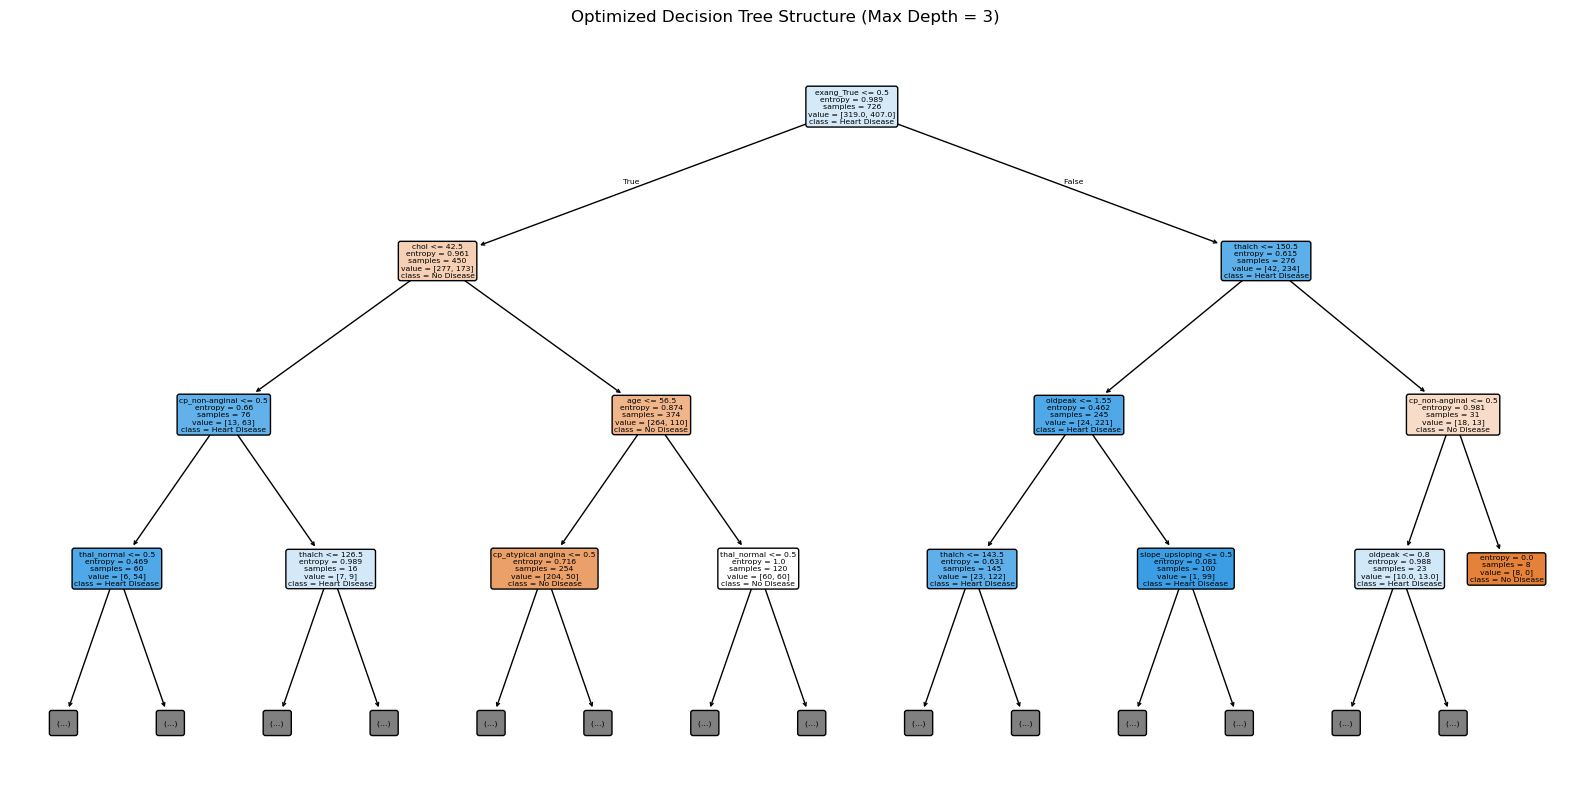


--- Top Features Influencing Heart Disease Prediction ---
               Feature  Importance
12          exang_True    0.311224
2                 chol    0.200334
4               thalch    0.107547
0                  age    0.088697
5              oldpeak    0.084808
17         thal_normal    0.070374
7   cp_atypical angina    0.048731
8       cp_non-anginal    0.037324
1             trestbps    0.025189
3                  fbs    0.011183


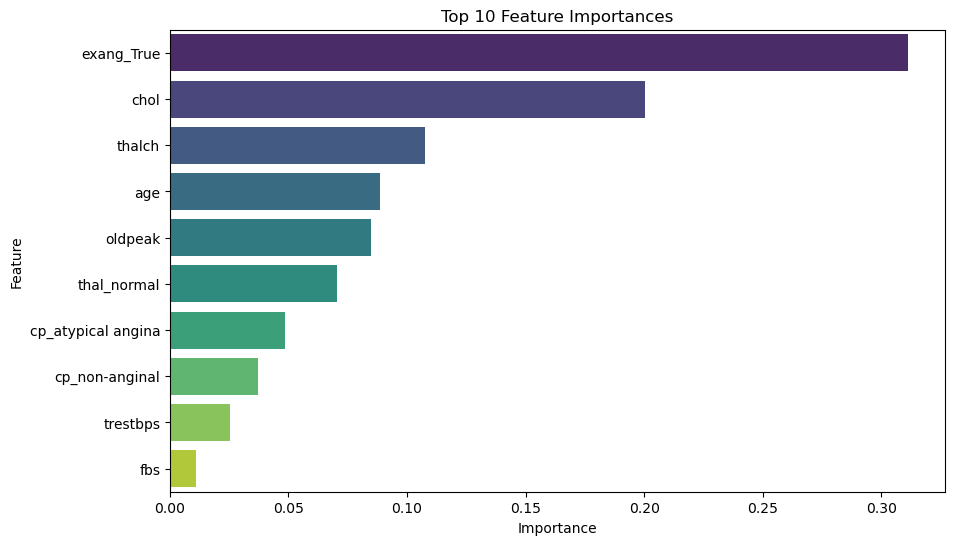

In [6]:
#Task 6: Model Evaluation, Visualization, and Analysis
from sklearn.tree import plot_tree

# Visualize Decision Tree Structure
plt.figure(figsize=(20, 10))
plot_tree(best_dt, feature_names=X.columns.tolist(), class_names=['No Disease', 'Heart Disease'], filled=True, rounded=True, max_depth=3)
plt.title('Optimized Decision Tree Structure (Max Depth = 3)')
plt.show()

# Feature Importances Analysis
importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance': best_dt.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("\n--- Top Features Influencing Heart Disease Prediction ---")
print(importances.head(10))

# Plot Feature Importances
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importances.head(10), palette='viridis', hue='Feature', legend=False)
plt.title('Top 10 Feature Importances')
plt.show()